# seekdb × hipVS — AMD GPU 批量向量检索

基于用户提供的 AMD 课程 Notebook 整理。按索引选择 `lib=vsag` 或 `lib=cuvs`，比较单条查询和批量算子，展示真实吞吐、Recall@10 和记分牌。

**七步流程**：①环境与硬件自检 ②工作原理 ③启动与准备数据 ④单查 CPU/GPU ⑤批量提速 ⑥召回与正确性 ⑦总结记分牌。

依赖课程 `seekdb-hipvs` 镜像内的批量查询后端，不需要模型 API Key。硬件型号、耗时和召回以本次运行输出为准；gfx1100 不能单独证明商业型号为 W7900。


In [1]:
from pathlib import Path
import os
import time
import uuid


def _notebook_directory():
    candidates = []
    for variable_name in ("__vsc_ipynb_file__", "__session__"):
        notebook_path = globals().get(variable_name)
        if notebook_path:
            candidates.append(Path(notebook_path).expanduser().resolve().parent)
    candidates.append(Path.cwd().resolve())

    for candidate in dict.fromkeys(candidates):
        if (candidate / "lib" / "seekdb_demo.py").is_file():
            return candidate
    return Path.cwd().resolve()


def _load_or_create_scope_uuid(file_path, timeout=5):
    deadline = time.monotonic() + timeout
    last_error = None

    while time.monotonic() < deadline:
        try:
            return str(uuid.UUID(file_path.read_text(encoding="ascii").strip()))
        except FileNotFoundError:
            generated_id = str(uuid.uuid4())
            try:
                descriptor = os.open(
                    file_path,
                    os.O_WRONLY | os.O_CREAT | os.O_EXCL,
                    0o600,
                )
            except FileExistsError:
                pass
            else:
                try:
                    with os.fdopen(descriptor, "w", encoding="ascii") as stream:
                        stream.write(generated_id + "\n")
                        stream.flush()
                        os.fsync(stream.fileno())
                except Exception:
                    file_path.unlink(missing_ok=True)
                    raise
                return generated_id
        except (OSError, ValueError) as exc:
            last_error = exc
        time.sleep(0.05)

    raise RuntimeError(
        f"Unable to read a valid telemetry UUID from {file_path}: {last_error}"
    )


_TELEMETRY_ID_FILE = _notebook_directory() / ".seekdb_telemetry_instance_id"
_TELEMETRY_INSTANCE_ID = _load_or_create_scope_uuid(_TELEMETRY_ID_FILE)
os.environ["SEEKDB_TELEMETRY_INSTANCE_ID"] = _TELEMETRY_INSTANCE_ID

In [2]:
import sys, os, subprocess, time, importlib

# ---- locate the sibling lib/ folder robustly (VS Code / JupyterLab / nbconvert) ----
def _find_lib():
    cands = []
    p = globals().get("__vsc_ipynb_file__")      # VS Code injects the .ipynb abs path
    if p: cands.append(os.path.dirname(os.path.abspath(p)))
    p = globals().get("__session__")             # some Jupyter builds expose the .ipynb path
    if p: cands.append(os.path.dirname(os.path.abspath(p)))
    cands.append(os.getcwd())                    # interactive Jupyter / nbconvert cwd = notebook dir
    for d in dict.fromkeys(cands):               # de-dup, keep order
        if d and os.path.isfile(os.path.join(d, "lib", "seekdb_demo.py")):
            return os.path.join(d, "lib")
    return os.path.join(os.getcwd(), "lib")      # last resort
_LIB = _find_lib(); sys.path.insert(0, _LIB)
import seekdb_demo as sk; importlib.reload(sk)
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

# ---- AMD showcase plot theme ----
AMD_RED, CPU_GRAY = "#ED1C24", "#5B6770"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#cccccc",
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
print("imports + theme ready.  lib =", _LIB)

imports + theme ready.  lib = /workspace/seekdb-hipvs-batch-demo/lib


## 1. 环境与硬件自检

确认我们真的运行在 **AMD GPU + ROCm** 上,且发行的 seekdb 二进制已**编译链接** hipVS/cuVS GPU 后端。


In [3]:
gi = sk.gpu_info(); si = sk.stack_info()
def _row(k, v): return {"项 / item": k, "值 / value": v}
env = pd.DataFrame([
    _row("GPU",               gi["name"]),
    _row("架构 arch",         "%s / RDNA3" % gi["gfx"]),
    _row("显存 VRAM",         ("%d MB total, %s MB used" % (gi["vram_total_mb"], gi["vram_used_mb"])) if gi["vram_total_mb"] else "n/a"),
    _row("ROCm",              gi["rocm"] or "n/a"),
    _row("seekdb 二进制 bin", "OK" if si["seekdb_bin"] else "MISSING"),
    _row("cuVS 桥接库 bridge","OK" if si["bridge"] else "MISSING"),
    _row("libcuvs 链接 link", "%d   (>0 = GPU backend compiled in)" % si["libcuvs_linked"]),
    _row("SEEKDB_HOME",       sk.SEEKDB),
])
env

,项 / item,值 / value
0,GPU,AMD Radeon Graphics
1,架构 arch,gfx1100 / RDNA3
2,显存 VRAM,"49136 MB total, 561 MB used"
3,ROCm,7.2.4
4,seekdb 二进制 bin,OK
5,cuVS 桥接库 bridge,OK
6,libcuvs 链接 link,3 (>0 = GPU backend compiled in)
7,SEEKDB_HOME,/seekdb_workspace


## 2. 工作原理

`lib=vsag` 选择 CPU VSAG/HNSW；课程镜像的 `lib=cuvs` 选择经纯 C bridge 接入的 hipVS CAGRA。

```text
seekdb SQL → obvsag C API → lib=vsag → CPU VSAG/HNSW
                        → lib=cuvs → C bridge → hipVS CAGRA → AMD ROCm
```

两个入口：
```sql
CREATE VECTOR INDEX i ON documents(embedding) WITH (distance=l2,type=hnsw,lib=cuvs);
CALL dbms_vector.batch_knn('t_cuvs','probes_4000',10,'bk_out');
```

课程说明不支持的查询场景回退 CPU；本演示验证无过滤 L2 查询，没有用 profile 证明过滤、删除或非 L2 的实际回退路由，不能据此承诺这些场景全部通过。它与本仓库另一个 HNSW 构建项目分别记录。


## 3. 启动 seekdb + 准备数据

启动课程镜像预装的 seekdb，在本项目 `run/obs1` 中建立专用实例。若 2881 端口属于别的实例，会明确停止本次启动，不自动结束其他服务。

建立同源 10,000 条、128 维向量的 CPU/GPU 表，M=16、ef_construction=200、ef_search=64。探针批量为 100/500/1000/2000/4000，来自同一组 100 个查询循环填充，并非 4000 个独立查询。


In [4]:
import json

_OBSERVER_BASE = Path.cwd() / "run" / "obs1"
if not sk.start_observer(str(_OBSERVER_BASE)):
    raise RuntimeError("seekdb observer failed to start")
print("seekdb version:", sk.version())

_telemetry_file = _OBSERVER_BASE / "run" / "telemetry.json"
_deadline = time.monotonic() + 15
_last_error = None

while time.monotonic() < _deadline:
    try:
        _telemetry_text = _telemetry_file.read_text(encoding="utf-8")
        telemetry = json.loads(_telemetry_text)
        break
    except (FileNotFoundError, json.JSONDecodeError, OSError) as exc:
        _last_error = exc
        time.sleep(0.25)
else:
    _log_file = _OBSERVER_BASE / "log" / "seekdb.log"
    _diagnostics = []
    if _log_file.is_file():
        _diagnostics = [
            line
            for line in _log_file.read_text(errors="replace").splitlines()
            if "telemetry" in line.lower()
        ][-20:]
    raise RuntimeError(
        f"telemetry.json was not generated within 15s: {_telemetry_file}\n"
        f"Last error: {_last_error}\n"
        f"Telemetry diagnostics:\n" + "\n".join(_diagnostics)
    )

print()
print(f"Complete telemetry.json: {_telemetry_file}")
print("telemetry.json parsed successfully; full runtime identifiers remain in the local file.")

ready
seekdb version: 5.7.25-OceanBase seekdb-v1.4.0.0

Complete telemetry.json: /workspace/seekdb-hipvs-batch-demo/run/obs1/run/telemetry.json
telemetry.json parsed successfully; full runtime identifiers remain in the local file.


In [5]:
N_INDEX     = 10000
PROBE_SIZES = (100, 500, 1000, 2000, 4000)
ok, err = sk.setup_data(N_INDEX, PROBE_SIZES)
assert ok, "data load failed: %s" % err[:300]
print("data loaded: t_cuvs (lib=cuvs, GPU) + t_vsag (lib=vsag, CPU), %d vectors each" % N_INDEX)
waited = sk.wait_index_ready("t_cuvs", timeout=90)
print("vector index ready (~%ds)  |  t_cuvs = %s rows,  t_vsag = %s rows" % (
    waited,
    sk.sql_rows("use vec; select count(*) from t_cuvs")[0][0],
    sk.sql_rows("use vec; select count(*) from t_vsag")[0][0]))

data loaded: t_cuvs (lib=cuvs, GPU) + t_vsag (lib=vsag, CPU), 10000 vectors each


vector index ready (~19s)  |  t_cuvs = 10000 rows,  t_vsag = 10000 rows


## 4. 单条查询：CPU vs GPU

各预热两次，分别取五次的最小耗时。此处端到端时间包含 mysql 客户端启动和 SQL 调用开销，不能直接当作索引内核延迟。单条 GPU 查询可能更慢，以实测为准。


single query   CPU (lib=vsag): 8.54 ms    GPU (lib=cuvs): 12.67 ms


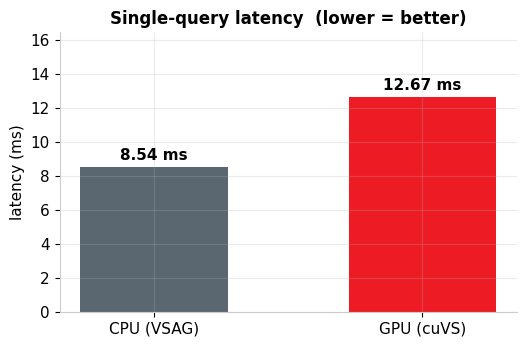

=> 单查 GPU 无收益。真正的加速在 *批量* -> 下一节。


In [6]:
for _ in range(2):
    sk.single_query("t_cuvs"); sk.single_query("t_vsag")           # warm up
cpu = min(sk.single_query("t_vsag") for _ in range(5)) * 1000
gpu = min(sk.single_query("t_cuvs") for _ in range(5)) * 1000
print("single query   CPU (lib=vsag): %.2f ms    GPU (lib=cuvs): %.2f ms" % (cpu, gpu))

fig, ax = plt.subplots(figsize=(5.4, 3.6))
bars = ax.bar(["CPU (VSAG)", "GPU (cuVS)"], [cpu, gpu], color=[CPU_GRAY, AMD_RED], width=0.55)
ax.bar_label(bars, fmt="%.2f ms", padding=3, fontweight="bold")
ax.set_ylabel("latency (ms)"); ax.set_title("Single-query latency  (lower = better)")
ax.set_ylim(0, max(cpu, gpu) * 1.3)
plt.tight_layout(); plt.show()
print("=> 单查 GPU 无收益。真正的加速在 *批量* -> 下一节。")

## 5. 批量提速：CPU 逐条 vs GPU 一次批量

CPU 使用探针表与 VSAG 的 lateral join；GPU 使用 `dbms_vector.batch_knn`。每个 N 各执行一次计时，报告的是本次样例，不是多轮统计结论。

SQL 会话超时设为 600 秒；SQL 失败立即报错。每个批次检查输出恰好 N×10 行，检查在计时结束后执行。避免默认 10 秒超时被误记为有效成绩。


In [7]:
df = sk.sweep(PROBE_SIZES)
df

,N,cpu_ms,gpu_ms,speedup,cpu_probes_s,gpu_probes_s
0,100,326.0,999.9,0.33,307,100
1,500,1474.2,909.3,1.62,339,550
2,1000,2924.4,912.2,3.21,342,1096
3,2000,5816.8,1116.0,5.21,344,1792
4,4000,11581.6,1318.6,8.78,345,3033


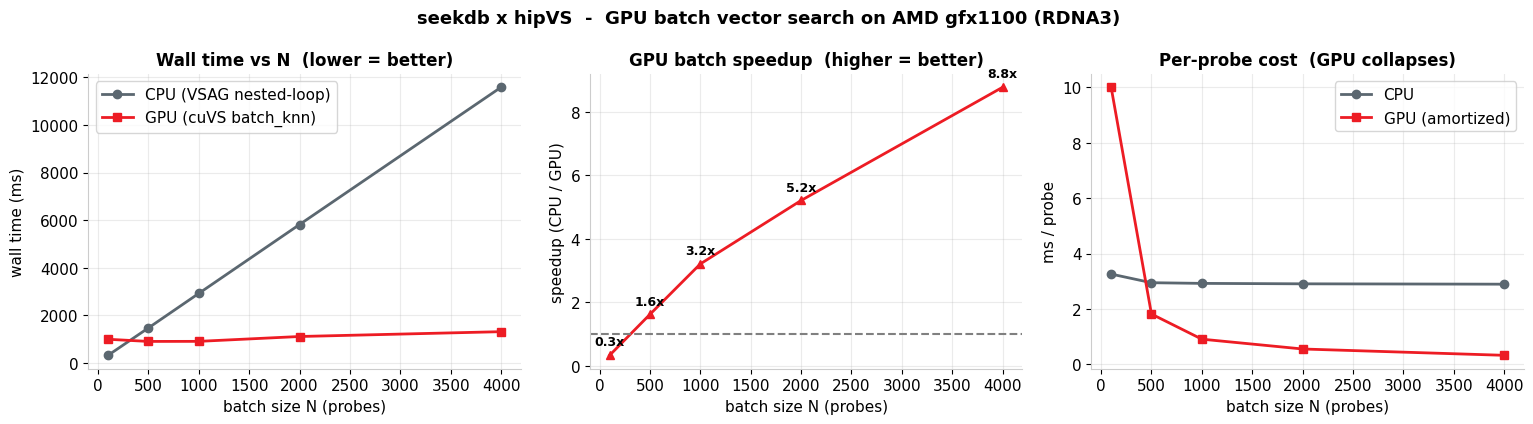

peak speedup: 8.8x at N=4000   ->  saved results/seekdb_hipvs_speedup.png + summary.csv


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.3))
ax[0].plot(df.N, df.cpu_ms, "o-", color=CPU_GRAY, lw=2, label="CPU (VSAG nested-loop)")
ax[0].plot(df.N, df.gpu_ms, "s-", color=AMD_RED, lw=2, label="GPU (cuVS batch_knn)")
ax[0].set_xlabel("batch size N (probes)"); ax[0].set_ylabel("wall time (ms)")
ax[0].set_title("Wall time vs N  (lower = better)"); ax[0].legend()

ax[1].plot(df.N, df.speedup, "^-", color=AMD_RED, lw=2); ax[1].axhline(1, ls="--", c="gray")
for x, y in zip(df.N, df.speedup):
    ax[1].annotate("%.1fx" % y, (x, y), textcoords="offset points", xytext=(0, 7),
                   ha="center", fontweight="bold", fontsize=9)
ax[1].set_xlabel("batch size N (probes)"); ax[1].set_ylabel("speedup (CPU / GPU)")
ax[1].set_title("GPU batch speedup  (higher = better)")

ax[2].plot(df.N, df.cpu_ms / df.N, "o-", color=CPU_GRAY, lw=2, label="CPU")
ax[2].plot(df.N, df.gpu_ms / df.N, "s-", color=AMD_RED, lw=2, label="GPU (amortized)")
ax[2].set_xlabel("batch size N (probes)"); ax[2].set_ylabel("ms / probe")
ax[2].set_title("Per-probe cost  (GPU collapses)"); ax[2].legend()

fig.suptitle("seekdb x hipVS  -  GPU batch vector search on AMD gfx1100 (RDNA3)",
             fontweight="bold", fontsize=13)
plt.tight_layout(); os.makedirs("results", exist_ok=True)
plt.savefig("results/seekdb_hipvs_speedup.png", dpi=120, bbox_inches="tight"); plt.show()
df.to_csv("results/summary.csv", index=False)
peak = df.speedup.max(); peakN = int(df.N.iloc[df.speedup.idxmax()])
print("peak speedup: %.1fx at N=%d   ->  saved results/seekdb_hipvs_speedup.png + summary.csv" % (peak, peakN))

## 6. 召回与正确性

对 100 个查询与镜像的 `gt_100x10.i32` 比较。展示当前 M=16、ef_search=64 下的 CPU/GPU Recall@10，不宣称这是经过等召回调优的性能比较。

后续检查会验证每个查询有十个不同结果，以及 GPU 单查与批量的实际一致率；只有测量结果支持时才能声称两者完全一致。


recall@10   CPU (VSAG): 0.6400    GPU (cuVS batch): 0.8840


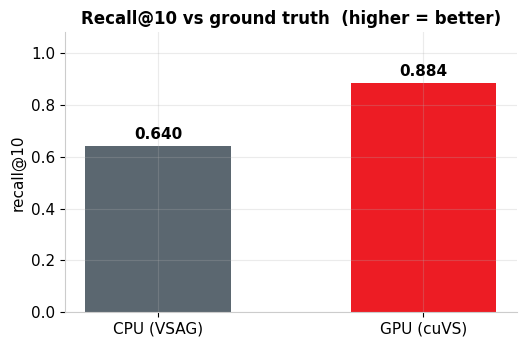

Recall values above are measured for this configuration; single/batch agreement is checked below.


In [9]:
sk.cpu_lateral(100); sk.gpu_batch(100)                    # fill cpu_out / bk_out
r_cpu = sk.recall_at_k("cpu_out"); r_gpu = sk.recall_at_k("bk_out")
print("recall@10   CPU (VSAG): %.4f    GPU (cuVS batch): %.4f" % (r_cpu, r_gpu))

fig, ax = plt.subplots(figsize=(5.4, 3.6))
bars = ax.bar(["CPU (VSAG)", "GPU (cuVS)"], [r_cpu, r_gpu], color=[CPU_GRAY, AMD_RED], width=0.55)
ax.bar_label(bars, fmt="%.3f", padding=3, fontweight="bold")
ax.set_ylabel("recall@10"); ax.set_title("Recall@10 vs ground truth  (higher = better)")
ax.set_ylim(0, 1.08)
plt.tight_layout(); plt.show()
print("Recall values above are measured for this configuration; single/batch agreement is checked below.")

## 7. 总结记分牌


In [10]:
peak = df.speedup.max(); peakN = int(df.N.iloc[df.speedup.idxmax()])
gpu_qps = int(df.gpu_probes_s.max()); cpu_qps = int(df.cpu_probes_s.max())
score = pd.DataFrame([
    {"指标 metric": "单查 single-query",       "结果 result": "GPU %.2f ms  vs  CPU %.2f ms   (no win)" % (gpu, cpu)},
    {"指标 metric": "批量峰值加速 batch peak",  "结果 result": "%.1fx  @ N=%d" % (peak, peakN)},
    {"指标 metric": "GPU 批量吞吐 throughput",  "结果 result": "%d probes/s   (CPU %d/s)" % (gpu_qps, cpu_qps)},
    {"指标 metric": "召回 recall@10",           "结果 result": "cuVS %.3f   vs   VSAG %.3f" % (r_gpu, r_cpu)},
    {"指标 metric": "驱动 how",                 "结果 result": "lib=cuvs + dbms_vector.batch_knn  (no env var)"},
])
score

,指标 metric,结果 result
0,单查 single-query,GPU 12.67 ms vs CPU 8.54 ms (no win)
1,批量峰值加速 batch peak,8.8x @ N=4000
2,GPU 批量吞吐 throughput,3033 probes/s (CPU 345/s)
3,召回 recall@10,cuVS 0.884 vs VSAG 0.640
4,驱动 how,lib=cuvs + dbms_vector.batch_knn (no env var)


### 结论与定位

结果由本次测量生成。重点观察批量增大时的吞吐变化、单条 GPU 固定开销和当前参数的召回。不要把批量查询加速写作 HNSW 索引构建加速，也不要将原课程截图中的 12.7× 固定为本次成绩。

GPU 价值探索：相似度 JOIN、批量向量打分和离线召回评测。源代码和改动说明见本目录 README。


In [11]:
# Additional checks: fail on incomplete data or missing query results.
import math
for table, expected in [("t_cuvs",10000),("t_vsag",10000)]+[("probes_%d" % v,v) for v in PROBE_SIZES]:
    actual=int(sk.sql_rows("use vec; select count(*) from "+table)[0][0])
    assert actual==expected,(table,actual,expected)
for table in ("cpu_out","bk_out"):
    count=int(sk.sql_rows("use vec; select count(*) from "+table)[0][0])
    assert count==1000,(table,count)
    groups=sk.sql_rows("use vec; select probe_id,count(*),count(distinct neighbor_id) from "+table+" group by probe_id")
    assert len(groups)==100 and all(int(v[1])==10 and int(v[2])==10 for v in groups)
assert list(df.N)==list(PROBE_SIZES)
assert all(math.isfinite(float(v)) and float(v)>0 for name in ("cpu_ms","gpu_ms","speedup") for v in df[name])
# Measure single/batch agreement instead of assuming it.
batch={}
for pid,nid in sk.sql_rows("use vec; select probe_id,neighbor_id from bk_out"):
    batch.setdefault(int(pid),set()).add(int(nid))
matches=0
single_hits=0
gt=sk._load_gt()
for pid,pv in sk.sql_rows("use vec; select id,pv from probes_100 order by id"):
    got=sk.sql_rows("use vec; select c1 from t_cuvs order by l2_distance(c2,'%s') approximate limit 10" % pv)
    single=set(int(row[0]) for row in got)
    assert len(single)==10 and all(0<=v<N_INDEX for v in single)
    matches += single==batch[int(pid)]
    single_hits += len(single & gt[int(pid)])
report={"completed":True,"rows":N_INDEX,"probe_sizes":list(PROBE_SIZES),
        "single_query_ms":{"cpu":cpu,"gpu":gpu},"batch_runs":df.to_dict(orient="records"),
        "recall_at_10":{"cpu":r_cpu,"gpu":r_gpu},
        "sql_results_validated":True,"gpu_single_batch_identical_queries":matches,"gpu_single_batch_checked_queries":100,"gpu_single_query_recall_at_10":single_hits/1000,"scope":"course preinstalled batch-query demo; not HNSW construction"}
Path("results/summary.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
print(json.dumps(report,indent=2))


{
  "completed": true,
  "rows": 10000,
  "probe_sizes": [
    100,
    500,
    1000,
    2000,
    4000
  ],
  "single_query_ms": {
    "cpu": 8.54232907295227,
    "gpu": 12.67133466899395
  },
  "batch_runs": [
    {
      "N": 100,
      "cpu_ms": 326.0,
      "gpu_ms": 999.9,
      "speedup": 0.33,
      "cpu_probes_s": 307,
      "gpu_probes_s": 100
    },
    {
      "N": 500,
      "cpu_ms": 1474.2,
      "gpu_ms": 909.3,
      "speedup": 1.62,
      "cpu_probes_s": 339,
      "gpu_probes_s": 550
    },
    {
      "N": 1000,
      "cpu_ms": 2924.4,
      "gpu_ms": 912.2,
      "speedup": 3.21,
      "cpu_probes_s": 342,
      "gpu_probes_s": 1096
    },
    {
      "N": 2000,
      "cpu_ms": 5816.8,
      "gpu_ms": 1116.0,
      "speedup": 5.21,
      "cpu_probes_s": 344,
      "gpu_probes_s": 1792
    },
    {
      "N": 4000,
      "cpu_ms": 11581.6,
      "gpu_ms": 1318.6,
      "speedup": 8.78,
      "cpu_probes_s": 345,
      "gpu_probes_s": 3033
    }
  ],
  "recall_at_